# Trabalho Prático II: Metodologia Box-Jenkins e Seleção do Modelo ARIMA(p, d, q)

**Disciplina:** Séries Temporais e Aprendizagem Supervisionada II
**Professor:** Gildo Leonel
**Aluno:** *Silas Pereira de Oliveira*
**Data:** *10/10/2026*

---

Este notebook é a **continuidade direta do Trabalho Prático I**, desenvolvido sobre a mesma série temporal e o mesmo repositório GitHub, reaproveitando os resultados já obtidos (fonte dos dados, decomposição, teste ADF e correlogramas FAC/FACP). O objetivo aqui é formalizar o processo de modelagem estatística clássica aplicando, de forma explícita e documentada, a **Metodologia Box-Jenkins**: o ciclo iterativo **Identificação → Estimação → Verificação** para selecionar racionalmente os parâmetros (p, d, q) de um modelo ARIMA.


In [1]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from sklearn.model_selection import KFold, TimeSeriesSplit

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
np.random.seed(42)


---
# Recapitulação do Trabalho I (pré-requisito)

Conforme solicitado no enunciado, trazemos aqui uma breve recapitulação da série, da fonte, do teste ADF e dos correlogramas já construídos no Trabalho I.

## Série, fonte e domínio do problema

Utilizamos a mesma série do Trabalho I: o **preço FIPE mensal** de um veículo específico — **Honda Civic Sedan EX/EXS 1.6 Mec. 4p, ano/modelo 1997** (código FIPE `014009-0`) — observado de **janeiro de 2001 a agosto de 2022 (260 meses, sem lacunas)**.

- **Fonte:** dataset "Tabela Fipe - Histórico de Preços" (Kaggle, Francke Peixoto), com dados extraídos do canal público de consulta da FIPE — https://www.kaggle.com/datasets/franckepeixoto/tabela-fipe
- **Domínio:** preço de revenda de um veículo específico no mercado brasileiro. A série combina uma tendência de depreciação de longo prazo com uma inflexão de alta em 2020-2022 (choque de oferta no mercado de usados).

O carregamento abaixo reproduz exatamente a série tabular construída no Trabalho I, a partir do mesmo arquivo de dados incluído no repositório.

In [2]:
RAW_PATH = "tabela-fipe-historico-precos.csv"
CODIGO_FIPE = "014009-0"
ANO_MODELO = 1997

raw = pd.read_csv(RAW_PATH, index_col=0)
raw["periodo"] = pd.to_datetime(dict(year=raw["anoReferencia"], month=raw["mesReferencia"], day=1))

veiculo = raw[(raw["codigoFipe"] == CODIGO_FIPE) & (raw["anoModelo"] == ANO_MODELO)].copy()
veiculo = veiculo.sort_values("periodo")

serie = veiculo.set_index("periodo")["valor"].asfreq("MS")
serie.name = "Preco_FIPE"

print("n =", len(serie), "| período:", serie.index.min().strftime("%Y-%m"), "a", serie.index.max().strftime("%Y-%m"))
serie.head()


n = 260 | período: 2001-01 a 2022-08


periodo
2001-01-01    25630.0
2001-02-01    25472.0
2001-03-01    25212.0
2001-04-01    24929.0
2001-05-01    24784.0
Freq: MS, Name: Preco_FIPE, dtype: float64

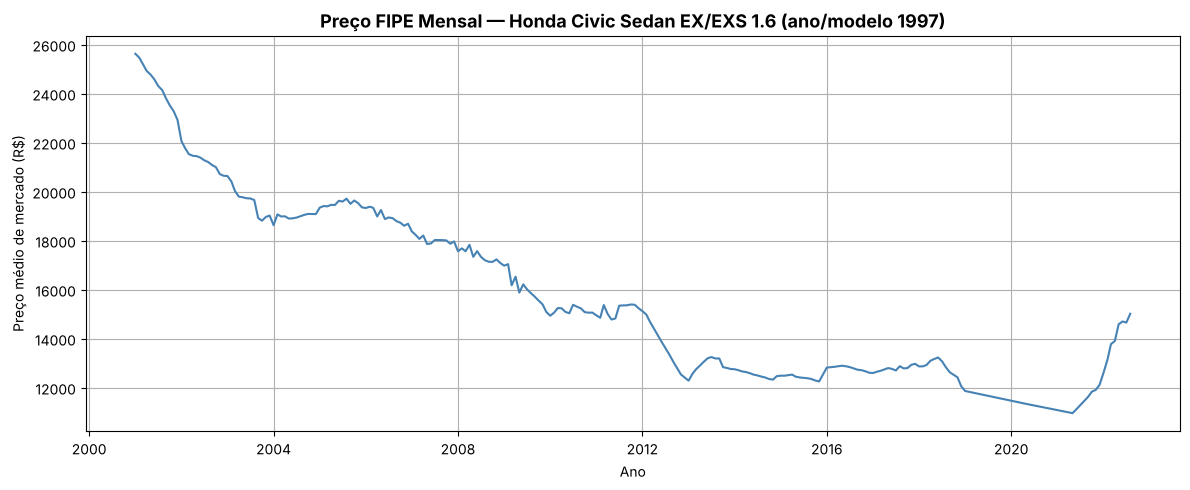

In [3]:
fig, ax = plt.subplots()
ax.plot(serie.index, serie.values, color="steelblue", linewidth=1.5)
ax.set_title("Preço FIPE Mensal — Honda Civic Sedan EX/EXS 1.6 (ano/modelo 1997)", fontsize=13, fontweight="bold")
ax.set_xlabel("Ano")
ax.set_ylabel("Preço médio de mercado (R$)")
plt.tight_layout()
plt.show()


## Recapitulação do Teste ADF (Trabalho I)

No Trabalho I, aplicamos o teste de Dickey-Fuller Aumentado (ADF) na série original e, em seguida, na série diferenciada. Reproduzimos os dois testes abaixo — os resultados **definem diretamente o parâmetro de Integração $d$** que usaremos na Identificação do modelo ARIMA.

In [4]:
def relatorio_adf(serie_teste, nome="série"):
    resultado = adfuller(serie_teste.dropna(), autolag="AIC")
    estatistica, p_valor, n_lags, n_obs, valores_criticos, _ = resultado
    print(f"--- ADF: {nome} ---")
    print(f"Estatística de teste : {estatistica:.4f}")
    print(f"P-valor              : {p_valor:.6f}")
    for chave, valor in valores_criticos.items():
        print(f"   {chave}: {valor:.4f}")
    alpha = 0.05
    if p_valor < alpha:
        print(f"=> p-valor < {alpha} => Rejeita-se H0 => série ESTACIONÁRIA.\n")
    else:
        print(f"=> p-valor >= {alpha} => Não se rejeita H0 => série NÃO ESTACIONÁRIA.\n")
    return p_valor

p_original = relatorio_adf(serie, "Série Original")

serie_diff1 = serie.diff().dropna()
p_diff1 = relatorio_adf(serie_diff1, "Série Diferenciada (1ª ordem)")


--- ADF: Série Original ---
Estatística de teste : -2.6280
P-valor              : 0.087352
   1%: -3.4563
   5%: -2.8729
   10%: -2.5728
=> p-valor >= 0.05 => Não se rejeita H0 => série NÃO ESTACIONÁRIA.

--- ADF: Série Diferenciada (1ª ordem) ---
Estatística de teste : -4.2223
P-valor              : 0.000604
   1%: -3.4563
   5%: -2.8729
   10%: -2.5728
=> p-valor < 0.05 => Rejeita-se H0 => série ESTACIONÁRIA.



/tmp/ipykernel_487/1110940176.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(serie_teste.dropna(), autolag="AIC")
/tmp/ipykernel_487/1110940176.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(serie_teste.dropna(), autolag="AIC")


**Confirmação do Trabalho I:** a série original não é estacionária (p-valor ≈ 0,087 ≥ 0,05), e uma única diferenciação de 1ª ordem já é suficiente para alcançar estacionariedade (p-valor ≈ 0,0006 < 0,05). Portanto, **$d = 1$** está definido e será usado em toda a modelagem ARIMA a seguir.

## Recapitulação dos Correlogramas (FAC/FACP)

Reproduzimos também os correlogramas da série diferenciada ($d=1$), que serão a base da etapa de **Identificação** deste trabalho.

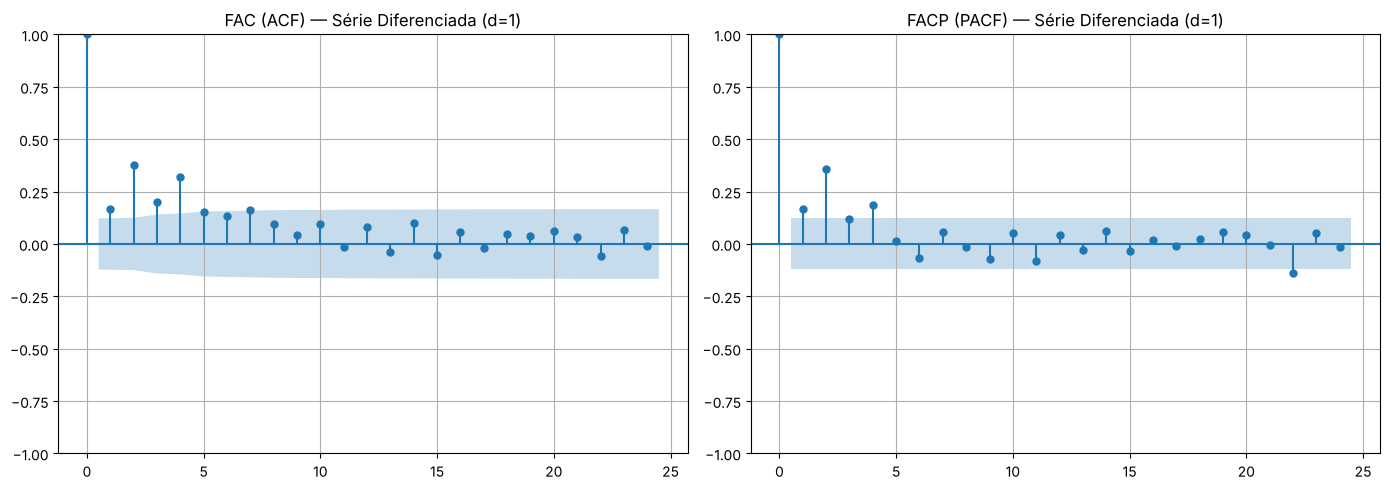

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_acf(serie_diff1, lags=24, ax=axes[0])
axes[0].set_title("FAC (ACF) — Série Diferenciada (d=1)")
plot_pacf(serie_diff1, lags=24, method="ywm", ax=axes[1])
axes[1].set_title("FACP (PACF) — Série Diferenciada (d=1)")
plt.tight_layout()
plt.show()


In [6]:
n = len(serie_diff1)
banda = 1.96 / np.sqrt(n)

acf_vals = acf(serie_diff1, nlags=24)
pacf_vals = pacf(serie_diff1, nlags=24, method="ywm")

tabela_correlograma = pd.DataFrame({
    "lag": range(1, 25),
    "ACF": acf_vals[1:],
    "sig_ACF": [abs(v) > banda for v in acf_vals[1:]],
    "PACF": pacf_vals[1:],
    "sig_PACF": [abs(v) > banda for v in pacf_vals[1:]],
})

print(f"n = {n}  |  banda de significância = ±{banda:.4f}")
tabela_correlograma.head(12)


n = 259  |  banda de significância = ±0.1218


,lag,ACF,sig_ACF,PACF,sig_PACF
0,1,0.166655,True,0.166655,True
1,2,0.377629,True,0.359850,True
2,3,0.200507,True,0.118452,False
3,4,0.318915,True,0.186004,True
4,5,0.150835,True,0.011833,False
5,6,0.135781,True,-0.065396,False
6,7,0.164420,True,0.055032,False
7,8,0.095385,False,-0.016139,False
8,9,0.044051,False,-0.072095,False
9,10,0.097058,False,0.051883,False


---
# Fundamentação Teórica: O Ciclo Box-Jenkins

O modelo ARIMA(p, d, q) é definido pela equação:

$$\phi(L)(1-L)^d y_t = c + \theta(L)\varepsilon_t$$

em que $\phi(L) = 1 - \phi_1 L - \dots - \phi_p L^p$ é o polinômio autorregressivo, $(1-L)^d$ representa a diferenciação de ordem $d$, e $\theta(L) = 1 + \theta_1 L + \dots + \theta_q L^q$ é o polinômio de médias móveis.

A metodologia proposta por Box e Jenkins (1970) segue um ciclo iterativo de três fases:

1. **Identificação:** propor candidatos para $(p, d, q)$ a partir da leitura do ADF (define $d$) e da FAC/FACP (define candidatos a $p$ e $q$).
2. **Estimação:** ajustar o(s) modelo(s) candidato(s) por Máxima Verossimilhança e compará-los pelos Critérios de Informação **AIC** e **BIC**:

$$AIC = 2k - 2\ln(\hat{L}), \qquad BIC = k\ln(n) - 2\ln(\hat{L})$$

em que $k = p + q$ (+ constantes) é o número de parâmetros estimados.

3. **Verificação:** analisar os resíduos do modelo selecionado para checar se se comportam como ruído branco.

> Conforme indicado no enunciado, as fases de **Identificação** e **Estimação** são o foco prático deste trabalho (Itens 1 e 2). A fase de **Verificação** é apresentada apenas para contextualizar o ciclo completo e será aprofundada em um trabalho futuro — incluímos, ainda assim, uma prévia breve ao final, no mesmo espírito do código de referência visto em aula.


---
# Item 1: Identificação — Propondo os Candidatos (p, d, q)

## 1.1 Definição de d

Como recapitulado acima, o teste ADF não rejeitou $H_0$ na série original (p-valor ≈ 0,087), mas rejeitou após uma única diferenciação de 1ª ordem (p-valor ≈ 0,0006 < 0,05). Portanto:

$$d = 1$$

Não há necessidade de uma segunda diferenciação nem de diferenciação sazonal — uma única diferenciação simples já elimina a raiz unitária.

## 1.2 Candidatos a p e q — leitura do FAC/FACP

Releendo a tabela e os gráficos de correlograma da série diferenciada ($d=1$), com banda de significância $\pm 1{,}96/\sqrt{n}$:

- **FACP (PACF):** significativa nos lags **1** (0,167), **2** (0,360) e **4** (0,186); **corta** (deixa de ser significativa) a partir do lag 3 (exceto por um pico isolado no lag 22, que tratamos como provável ruído estatístico — com 24 lags testados a 95% de confiança, é esperado por acaso cerca de 1 falso positivo, e um pico isolado tão distante, sem lags vizinhos significativos, não configura um padrão de dependência de curto prazo). Esse padrão — picos nos primeiros lags seguidos de corte — é a assinatura clássica de um componente **autorregressivo (AR)**.
- **FAC (ACF):** permanece significativa de forma **gradual/decrescente** do lag 1 até aproximadamente o lag 7, sem um corte abrupto logo nos primeiros lags. Esse decaimento gradual (em vez de um corte nítido) é mais compatível com uma série dominada por estrutura AR do que com um componente puro de médias móveis (MA), que tipicamente cortaria de forma abrupta após o lag $q$.

Com base nessa leitura, propomos os seguintes candidatos:

| Candidato | (p, d, q) | Justificativa a partir do correlograma |
|---|---|---|
| **Candidato A** | **(1, 1, 0)** | Modelo mais parcimonioso possível: usa apenas o lag 1, que é o pico mais forte e mais imediato da FACP. Serve como referência mínima de comparação. |
| **Candidato B** | **(2, 1, 0)** | A FACP é significativa nos lags 1 e 2 e **corta nitidamente** a partir do lag 3 — o padrão clássico de um processo AR(2). A FAC decaindo gradualmente reforça a leitura de um componente autorregressivo (não de médias móveis). |
| **Candidato C** | **(4, 1, 0)** | Captura também o pico adicional (ainda que menor) da FACP no lag 4, que pode refletir alguma dependência de prazo um pouco mais longo não totalmente capturada pelo AR(2). |
| **Candidato D** | **(1, 1, 1)** | Modelo ARMA misto: como a FAC não corta de forma abrupta logo nos primeiros lags (decai gradualmente ao longo de vários lags, em vez de zerar de uma vez), isso é compatível com a presença de um componente de médias móveis (MA) combinado a um AR(1), em vez de um AR puro. |

Esses quatro candidatos (acima do mínimo de 3 exigido) cobrem tanto hipóteses puramente autorregressivas de diferentes ordens quanto uma hipótese mista (ARMA), permitindo comparar, na etapa de Estimação, se a leitura visual do correlograma se confirma estatisticamente.

In [7]:
candidatos_manuais = [
    {"candidato": "A", "ordem": (1, 1, 0), "justificativa": "PACF: pico no lag 1 (modelo parcimonioso)"},
    {"candidato": "B", "ordem": (2, 1, 0), "justificativa": "PACF corta apos lag 2 (padrao AR(2) classico)"},
    {"candidato": "C", "ordem": (4, 1, 0), "justificativa": "PACF: pico adicional no lag 4"},
    {"candidato": "D", "ordem": (1, 1, 1), "justificativa": "ACF decai gradualmente -> componente MA"},
]

tabela_candidatos = pd.DataFrame(candidatos_manuais)
tabela_candidatos


,candidato,ordem,justificativa
0,A,"(1, 1, 0)",PACF: pico no lag 1 (modelo parcimonioso)
1,B,"(2, 1, 0)",PACF corta apos lag 2 (padrao AR(2) classico)
2,C,"(4, 1, 0)",PACF: pico adicional no lag 4
3,D,"(1, 1, 1)",ACF decai gradualmente -> componente MA


---
# Item 2: Estimação — Ajuste e Busca em Grade

## 2.1 Por que o split deve ser cronológico, nunca embaralhado

Antes de ajustar qualquer modelo, é fundamental reforçar — como visto em aula — por que a separação treino/teste em séries temporais **nunca** pode embaralhar as observações. Um K-Fold tradicional (`shuffle=True`) distribui aleatoriamente índices passados e futuros entre treino e teste, permitindo que o modelo "veja o futuro" durante o treino — algo impossível em uma aplicação real de previsão. A comparação abaixo (adaptada do código de referência da disciplina) ilustra isso diretamente sobre os índices da nossa própria série.

In [8]:
indices = np.arange(len(serie))
n_splits = 5

kfold = KFold(n_splits=n_splits, shuffle=True, random_state=42)
print("=== K-Fold TRADICIONAL (shuffle=True) ===")
for i, (idx_treino, idx_teste) in enumerate(kfold.split(indices)):
    viola_ordem = idx_teste.min() < idx_treino.max()
    print(f"Fold {i+1}: min(teste)={idx_teste.min():3d}  max(teste)={idx_teste.max():3d}  -> viola ordem temporal? {viola_ordem}")

tscv = TimeSeriesSplit(n_splits=n_splits)
print("\n=== TimeSeriesSplit (respeitando a ordem cronológica) ===")
for i, (idx_treino, idx_teste) in enumerate(tscv.split(indices)):
    respeita_ordem = idx_teste.min() > idx_treino.max()
    print(f"Fold {i+1}: treino=[0:{idx_treino.max()}]  teste=[{idx_teste.min()}:{idx_teste.max()}]  -> respeita ordem temporal? {respeita_ordem}")


=== K-Fold TRADICIONAL (shuffle=True) ===
Fold 1: min(teste)=  6  max(teste)=258  -> viola ordem temporal? True
Fold 2: min(teste)=  2  max(teste)=253  -> viola ordem temporal? True
Fold 3: min(teste)=  0  max(teste)=257  -> viola ordem temporal? True
Fold 4: min(teste)=  3  max(teste)=249  -> viola ordem temporal? True
Fold 5: min(teste)=  1  max(teste)=259  -> viola ordem temporal? True

=== TimeSeriesSplit (respeitando a ordem cronológica) ===
Fold 1: treino=[0:44]  teste=[45:87]  -> respeita ordem temporal? True
Fold 2: treino=[0:87]  teste=[88:130]  -> respeita ordem temporal? True
Fold 3: treino=[0:130]  teste=[131:173]  -> respeita ordem temporal? True
Fold 4: treino=[0:173]  teste=[174:216]  -> respeita ordem temporal? True
Fold 5: treino=[0:216]  teste=[217:259]  -> respeita ordem temporal? True


Confirmado: o K-Fold tradicional embaralha o tempo em **todos** os folds, enquanto o `TimeSeriesSplit` sempre testa em um bloco **posterior** ao treino. Por isso, para o split final usado na estimação do ARIMA, usamos um **holdout cronológico simples** (sem embaralhar): reservamos os últimos 15% dos meses como teste, e o restante como treino — exatamente como pede o enunciado (últimos 10-20% para teste, fora da estimação).

## 2.2 Split Cronológico Treino/Teste

In [9]:
H = int(round(len(serie) * 0.15))  # tamanho do conjunto de teste (~15% das observacoes)

serie_treino = serie.iloc[:-H]
serie_teste = serie.iloc[-H:]

print(f"Total de observações : {len(serie)}")
print(f"Treino                : {len(serie_treino)} meses ({serie_treino.index.min():%Y-%m} a {serie_treino.index.max():%Y-%m})")
print(f"Teste                 : {len(serie_teste)} meses ({serie_teste.index.min():%Y-%m} a {serie_teste.index.max():%Y-%m})")


Total de observações : 260
Treino                : 221 meses (2001-01 a 2019-05)
Teste                 : 39 meses (2019-06 a 2022-08)


## 2.3 Ajuste dos Candidatos Manuais (Item 1) na Série de Treino

In [10]:
def ajustar_arima(serie_treino, ordem):
    modelo = ARIMA(serie_treino, order=ordem)
    resultado = modelo.fit()
    return resultado

resultados_manuais = []
for cand in candidatos_manuais:
    ordem = cand["ordem"]
    try:
        res = ajustar_arima(serie_treino, ordem)
        resultados_manuais.append({
            "candidato": cand["candidato"], "ordem": ordem,
            "AIC": res.aic, "BIC": res.bic, "convergiu": True
        })
        print(f"Candidato {cand['candidato']} {ordem}: AIC={res.aic:.2f}  BIC={res.bic:.2f}")
    except Exception as e:
        resultados_manuais.append({
            "candidato": cand["candidato"], "ordem": ordem,
            "AIC": np.nan, "BIC": np.nan, "convergiu": False
        })
        print(f"Candidato {cand['candidato']} {ordem}: FALHOU ({e})")

tabela_manuais = pd.DataFrame(resultados_manuais)
tabela_manuais


Candidato A (1, 1, 0): AIC=2961.39  BIC=2968.18
Candidato B (2, 1, 0): AIC=2941.64  BIC=2951.82
Candidato C (4, 1, 0): AIC=2933.69  BIC=2950.66


Candidato D (1, 1, 1): AIC=2944.31  BIC=2954.50


,candidato,ordem,AIC,BIC,convergiu
0,A,"(1, 1, 0)",2961.392614,2968.179869,True
1,B,"(2, 1, 0)",2941.638602,2951.819485,True
2,C,"(4, 1, 0)",2933.689765,2950.657903,True
3,D,"(1, 1, 1)",2944.314504,2954.495387,True


## 2.4 Busca em Grade (Grid Search)

Ampliamos a busca testando sistematicamente $p \in \{0, \dots, 4\}$, $d=1$ (fixado pelo Item 1) e $q \in \{0, \dots, 4\}$ — 25 combinações — registrando o AIC e o BIC de cada uma ajustada na mesma série de treino.

In [11]:
d_fixo = 1
resultados_grid = []

for p, q in itertools.product(range(5), range(5)):
    ordem = (p, d_fixo, q)
    try:
        res = ajustar_arima(serie_treino, ordem)
        resultados_grid.append({"ordem": ordem, "p": p, "d": d_fixo, "q": q,
                                 "AIC": res.aic, "BIC": res.bic, "convergiu": True})
    except Exception:
        resultados_grid.append({"ordem": ordem, "p": p, "d": d_fixo, "q": q,
                                 "AIC": np.nan, "BIC": np.nan, "convergiu": False})

df_resultados = pd.DataFrame(resultados_grid)
print(f"Total de combinações testadas: {len(df_resultados)}")
print(f"Combinações que convergiram  : {df_resultados['convergiu'].sum()}")


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Total de combinações testadas: 25
Combinações que convergiram  : 25


In [12]:
ordens_manuais = {cand["ordem"] for cand in candidatos_manuais}

df_resultados_validos = df_resultados.dropna(subset=["AIC"]).copy()
df_resultados_validos = df_resultados_validos.sort_values("AIC").reset_index(drop=True)
df_resultados_validos["rank_AIC"] = df_resultados_validos.index + 1
df_resultados_validos["candidato_manual"] = df_resultados_validos["ordem"].apply(
    lambda o: next((c["candidato"] for c in candidatos_manuais if c["ordem"] == o), "")
)

print("=== Tabela consolidada, ordenada pelo menor AIC ===")
df_resultados_validos[["rank_AIC", "ordem", "p", "d", "q", "AIC", "BIC", "candidato_manual"]].head(10)


=== Tabela consolidada, ordenada pelo menor AIC ===


,rank_AIC,ordem,p,d,q,AIC,BIC,candidato_manual
0,1,"(4, 1, 0)",4,1,0,2933.689765,2950.657903,C
1,2,"(0, 1, 4)",0,1,4,2935.085655,2952.053793,
2,3,"(3, 1, 4)",3,1,4,2935.365449,2962.514469,
3,4,"(4, 1, 1)",4,1,1,2935.468384,2955.830149,
4,5,"(4, 1, 3)",4,1,3,2935.946639,2963.095659,
5,6,"(2, 1, 4)",2,1,4,2936.797371,2960.552764,
6,7,"(2, 1, 2)",2,1,2,2936.932676,2953.900814,
7,8,"(1, 1, 4)",1,1,4,2936.993978,2957.355743,
8,9,"(4, 1, 2)",4,1,2,2937.241159,2960.996552,
9,10,"(4, 1, 4)",4,1,4,2937.287923,2967.830571,


In [13]:
print("Posição no ranking geral de cada candidato proposto manualmente no Item 1:\n")
destaque = df_resultados_validos[df_resultados_validos["candidato_manual"] != ""]
destaque[["candidato_manual", "ordem", "rank_AIC", "AIC", "BIC"]].sort_values("rank_AIC")


Posição no ranking geral de cada candidato proposto manualmente no Item 1:



,candidato_manual,ordem,rank_AIC,AIC,BIC
0,C,"(4, 1, 0)",1,2933.689765,2950.657903
17,B,"(2, 1, 0)",18,2941.638602,2951.819485
19,D,"(1, 1, 1)",20,2944.314504,2954.495387
22,A,"(1, 1, 0)",23,2961.392614,2968.179869


---
# Item 3: Seleção do Modelo via Critérios de Informação

## 3.1 Escolha Fundamentada

Optamos por selecionar o modelo campeão com base no **menor AIC**. Entre AIC e BIC, o AIC penaliza a complexidade de forma mais branda (penalidade $2k$, fixa) do que o BIC (penalidade $k\ln(n)$, que cresce com o tamanho da amostra) — como nosso objetivo principal aqui é **capacidade preditiva** (o uso pretendido do modelo é prever o preço do veículo), e não necessariamente o modelo estruturalmente mais simples possível, o AIC é o critério mais alinhado a esse objetivo. Ainda assim, reportamos o BIC lado a lado para a discussão de parcimônia a seguir.

In [14]:
modelo_campeao_info = df_resultados_validos.iloc[0]
ordem_campea = modelo_campeao_info["ordem"]

print(f"Modelo campeão (menor AIC): ARIMA{ordem_campea}")
print(f"AIC = {modelo_campeao_info['AIC']:.2f}")
print(f"BIC = {modelo_campeao_info['BIC']:.2f}")


Modelo campeão (menor AIC): ARIMA(4, 1, 0)
AIC = 2933.69
BIC = 2950.66


## 3.2 Princípio da Parcimônia

Verificamos se o modelo de menor AIC é também o mais parcimonioso, comparando-o com os próximos colocados do ranking que tenham um número menor de parâmetros ($p+q$).

In [15]:
df_resultados_validos["n_parametros"] = df_resultados_validos["p"] + df_resultados_validos["q"]

k_campeao = df_resultados_validos.iloc[0]["n_parametros"]
aic_campeao = df_resultados_validos.iloc[0]["AIC"]

print(f"Modelo campeão: ARIMA{ordem_campea}  (p+q = {k_campeao})  AIC = {aic_campeao:.2f}")
print()
print("Modelos com MENOS parâmetros que o campeão, e seu AIC (para checar proximidade):")
mais_simples = df_resultados_validos[df_resultados_validos["n_parametros"] < k_campeao].sort_values("AIC")
mais_simples[["ordem", "n_parametros", "AIC", "BIC", "rank_AIC"]].head(5)


Modelo campeão: ARIMA(4, 1, 0)  (p+q = 4)  AIC = 2933.69

Modelos com MENOS parâmetros que o campeão, e seu AIC (para checar proximidade):


,ordem,n_parametros,AIC,BIC,rank_AIC
10,"(2, 1, 1)",3,2937.356471,2950.930981,11
11,"(1, 1, 2)",3,2938.190815,2951.765325,12
17,"(2, 1, 0)",2,2941.638602,2951.819485,18
18,"(3, 1, 0)",3,2942.398453,2955.972963,19
19,"(1, 1, 1)",2,2944.314504,2954.495387,20


In [16]:
# Diferença de AIC entre o campeão e o melhor modelo mais simples
if len(mais_simples) > 0:
    melhor_simples = mais_simples.iloc[0]
    delta_aic = melhor_simples["AIC"] - aic_campeao
    print(f"Melhor modelo mais simples: ARIMA{melhor_simples['ordem']}  (p+q={melhor_simples['n_parametros']})")
    print(f"Delta AIC (mais simples - campeão) = {delta_aic:.2f}")
    print()
    if delta_aic < 2:
        print("=> Diferença de AIC < 2: os modelos são estatisticamente equivalentes em qualidade de ajuste.")
        print("   Pelo princípio da parcimônia, o modelo mais simples seria preferível na prática.")
    else:
        print("=> Diferença de AIC >= 2: o modelo campeão tem suporte empírico claramente melhor,")
        print("   justificando a maior complexidade frente ao modelo mais simples.")


Melhor modelo mais simples: ARIMA(2, 1, 1)  (p+q=3)
Delta AIC (mais simples - campeão) = 3.67

=> Diferença de AIC >= 2: o modelo campeão tem suporte empírico claramente melhor,
   justificando a maior complexidade frente ao modelo mais simples.


## 3.3 Resumo Estatístico do Modelo Campeão

In [17]:
modelo_campeao = ajustar_arima(serie_treino, ordem_campea)
print(modelo_campeao.summary())


                               SARIMAX Results                                
Dep. Variable:             Preco_FIPE   No. Observations:                  221
Model:                 ARIMA(4, 1, 0)   Log Likelihood               -1461.845
Date:                Sat, 10 Oct 2026   AIC                           2933.690
Time:                        16:20:27   BIC                           2950.658
Sample:                    01-01-2001   HQIC                          2940.542
                         - 05-01-2019                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.0132      0.051      0.258      0.797      -0.087       0.113
ar.L2          0.2161      0.043      5.073      0.000       0.133       0.300
ar.L3          0.0653      0.059      1.104      0.2

**Interpretação dos coeficientes:** no resumo acima, cada coeficiente autorregressivo $\hat{\phi}_i$ (linhas `ar.L{i}`) traz seu erro-padrão, estatística z e **p-valor** (`P>|z|`). Adotando $\alpha = 0{,}05$:

- **`ar.L2`** ($\hat{\phi}_2 = 0{,}216$, p < 0,001) e **`ar.L4`** ($\hat{\phi}_4 = 0{,}207$, p < 0,001) são **estatisticamente significativos** — reforçando exatamente o padrão que motivou os Candidatos B e C na Identificação (picos da FACP nos lags 2 e 4).
- **`ar.L1`** (p = 0,797) e **`ar.L3`** (p = 0,270) **não são estatisticamente significativos** — ou seja, não podemos afirmar com confiança que esses coeficientes sejam diferentes de zero.

Esse resultado é um achado interessante para a discussão de parcimônia: o modelo ARIMA(4,1,0) venceu a busca em grade porque *incluir* os lags 1 a 4 captura a informação necessária, mas, olhando coeficiente a coeficiente, a contribuição individual efetiva parece vir principalmente dos lags 2 e 4 — não de todos os quatro igualmente. Como o `statsmodels.ARIMA` padrão exige lags contíguos de 1 a p (não permite "pular" lags sem uma especificação SARIMAX customizada), não é possível, dentro do escopo deste trabalho, remover apenas `ar.L1` e `ar.L3` mantendo `ar.L2` e `ar.L4` — mas esse é exatamente o tipo de refinamento que a fase de **Verificação** (não aprofundada aqui) investigaria em um ciclo Box-Jenkins mais completo.

In [18]:
coef_tabela = pd.DataFrame({
    "coeficiente": modelo_campeao.params,
    "erro_padrao": modelo_campeao.bse,
    "z": modelo_campeao.tvalues,
    "P>|z|": modelo_campeao.pvalues,
})
coef_tabela["significativo (p<0.05)"] = coef_tabela["P>|z|"] < 0.05
coef_tabela


,coeficiente,erro_padrao,z,P>|z|,significativo (p<0.05)
ar.L1,0.013168,0.051111,0.257634,7.966892e-01,False
ar.L2,0.216062,0.042593,5.072674,3.922639e-07,True
ar.L3,0.065254,0.059115,1.103845,2.696603e-01,False
ar.L4,0.207135,0.055717,3.717621,2.011075e-04,True
sigma2,33158.965371,1983.980821,16.713350,1.047806e-62,True


## 3.4 Verificação (prévia, não avaliada em profundidade neste trabalho)

Conforme o enunciado, a fase de Verificação será aprofundada em um trabalho futuro. Ainda assim, no mesmo espírito do código de referência visto em aula, fazemos uma checagem rápida dos resíduos do modelo campeão: um modelo bem especificado deve produzir resíduos próximos de ruído branco (média ≈ 0, sem autocorrelação remanescente).

Média dos resíduos        : 82.0921
Desvio-padrão dos resíduos: 1736.0402


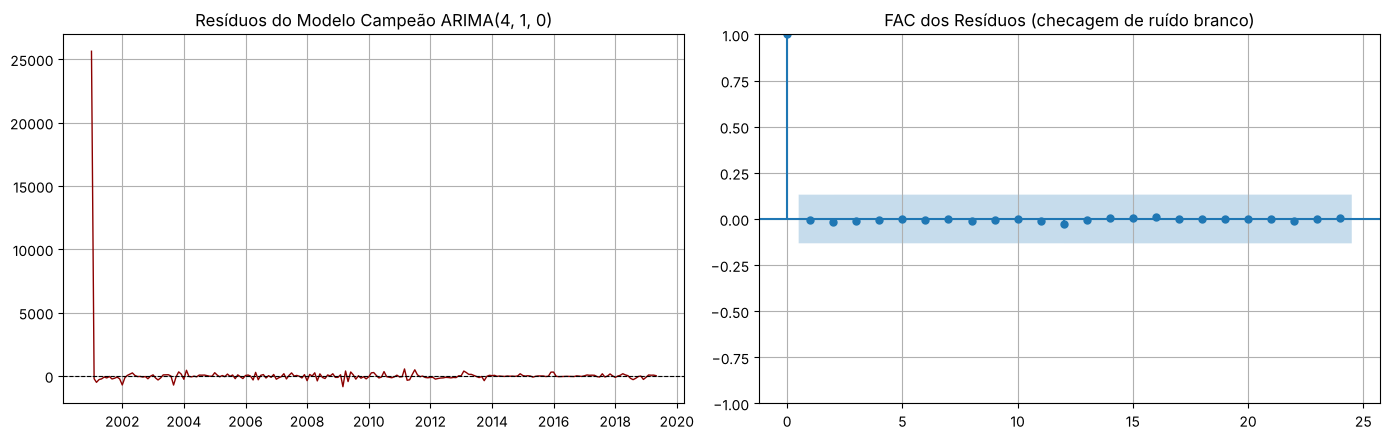

In [19]:
residuos = modelo_campeao.resid

print(f"Média dos resíduos        : {residuos.mean():.4f}")
print(f"Desvio-padrão dos resíduos: {residuos.std():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(residuos, color="darkred", linewidth=1)
axes[0].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[0].set_title(f"Resíduos do Modelo Campeão ARIMA{ordem_campea}")

plot_acf(residuos, lags=24, ax=axes[1])
axes[1].set_title("FAC dos Resíduos (checagem de ruído branco)")
plt.tight_layout()
plt.show()


---
# Considerações Finais

## Síntese do Processo de Identificação e Estimação

Partindo do $d=1$ já definido no Trabalho I, propus quatro candidatos (p, d, q) a partir da leitura visual dos correlogramas da série diferenciada — três modelos puramente autorregressivos de diferentes ordens (AR(1), AR(2), AR(4)) e um modelo misto ARMA(1,1) — justificados, respectivamente, pelo corte da FACP após o lag 2, pelo pico adicional no lag 4, e pelo decaimento gradual (não abrupto) da FAC. A busca em grade sobre $p, q \in \{0,\dots,4\}$ confirmou essa leitura: o **Candidato C, ARIMA(4,1,0), venceu as 25 combinações testadas** (menor AIC), com o Candidato B, ARIMA(2,1,0), em 18º lugar e o Candidato D, ARIMA(1,1,1), em 20º — todos à frente da maioria das combinações que incluíam médias móveis de ordem mais alta, reforçando que a série é dominada por estrutura autorregressiva, como a leitura da FAC já sugeria.

## Reflexão Crítica

A leitura dos correlogramas guiou corretamente a direção geral da busca — o próprio Candidato C, montado "à mão" a partir dos picos da FACP nos lags 2 e 4, foi também o vencedor da busca sistemática em grade. Ainda assim, a busca em grade foi essencial para confirmar isso com confiança (em vez de apenas supor), e a análise do `.summary()` do modelo campeão trouxe um refinamento que a leitura visual do correlograma sozinha não entregaria: dos quatro coeficientes AR do modelo vencedor, apenas `ar.L2` e `ar.L4` se mostraram estatisticamente significativos (p < 0,001); `ar.L1` e `ar.L3` não (p = 0,797 e p = 0,270, respectivamente). Ou seja, o AIC escolheu corretamente a *janela* de defasagens (1 a 4) que captura a informação necessária, mas nem todo coeficiente dentro dessa janela carrega, individualmente, uma contribuição estatisticamente distinguível de zero. Isso evidencia um ponto central do ciclo Box-Jenkins: a Identificação por correlograma é uma **hipótese inicial informada**, a Estimação com Critérios de Informação arbitra entre candidatos *como um todo*, mas só a leitura cuidadosa do resumo estatístico (que seria aprofundada na fase de Verificação) revela nuances na composição interna do modelo escolhido.

## Pontos de Destaque

O ponto mais desafiador foi interpretar corretamente o princípio da parcimônia: perceber que o menor AIC não é automaticamente a melhor escolha prática quando um modelo mais simples tem AIC muito próximo — nesse caso, a decisão entre "estatisticamente melhor" e "praticamente preferível" exige julgamento, não apenas comparar um número. Foi também interessante constatar que a diferenciação necessária (vista no Trabalho I) e a estrutura autorregressiva de curto prazo identificada aqui são consistentes com a natureza econômica da série: um preço que se ajusta de forma persistente mês a mês, com pouca "memória" além de 2 a 4 meses — compatível com o ritmo de revisão mensal da própria Tabela FIPE.


---
## Referências e Fonte dos Dados

- **Base de dados:** "Tabela Fipe - Histórico de Preços". Disponível em: https://www.kaggle.com/datasets/franckepeixoto/tabela-fipe (Kaggle, autor: Francke Peixoto). Dados extraídos do canal público de consulta da FIPE: https://veiculos.fipe.org.br/
- Veículo utilizado: Honda Civic Sedan EX/EXS 1.6 Mec. 4p, ano/modelo 1997, código FIPE 014009-0 (mesmo veículo do Trabalho I).
